# SmartFactory AI - Etape 3 : K-Means (apprentissage non supervisé)
Objectifs :
1. Trouver des groupes de comportements des machines (sans utiliser la cible).
2. Vérifier si un cluster concentre les pannes (groupe « à risque »).
3. Détecter des machines atypiques avec la distance au centroïde.

Prérequis : notebooks 01 et 02 exécutés.

## 1. Imports, chemins et chargement

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

# Détection automatique du dossier du projet
BASE = Path.cwd()
if not (BASE / "data").exists():
    BASE = BASE.parent
DATA, MODELS = BASE / "data", BASE / "models"
print("Projet :", BASE)

train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
feature_cols = joblib.load(MODELS / "feature_cols.pkl")

# K-Means utilise les variables capteurs (on exclut Type, variable catégorielle encodée)
km_cols = [c for c in feature_cols if c != "Type_enc"]
X_train, y_train = train[km_cols], train["target"]
X_test, y_test = test[km_cols], test["target"]
print("Variables utilisées :", km_cols)
print(X_train.shape, X_test.shape)

Projet : c:\Users\ghait\Desktop\Projet Python
Variables utilisées : ['Air_temperature', 'Process_temperature', 'Rotational_speed', 'Torque', 'Tool_wear', 'Temp_diff', 'Power', 'Torque_x_Wear']
(8000, 8) (2000, 8)


In [3]:
import shutil
from pathlib import Path

BASE = Path(r"c:\Users\ghait\Desktop\Projet Python")
WRONG = BASE.parent                      # c:\Users\ghait\Desktop

for folder in ["data", "models"]:
    src, dst = WRONG / folder, BASE / folder
    dst.mkdir(exist_ok=True)
    if src.exists():
        for f in src.iterdir():
            if f.is_file() and not (dst / f.name).exists():
                shutil.copy2(f, dst / f.name)
                print("Copié :", f.name, "->", dst)

print("\ndata   :", sorted(p.name for p in (BASE / "data").iterdir()))
print("models :", sorted(p.name for p in (BASE / "models").iterdir()))

Copié : ai4i_clean.csv -> c:\Users\ghait\Desktop\Projet Python\data
Copié : test.csv -> c:\Users\ghait\Desktop\Projet Python\data
Copié : test_pca.csv -> c:\Users\ghait\Desktop\Projet Python\data
Copié : train.csv -> c:\Users\ghait\Desktop\Projet Python\data
Copié : train_pca.csv -> c:\Users\ghait\Desktop\Projet Python\data
Copié : feature_cols.pkl -> c:\Users\ghait\Desktop\Projet Python\models
Copié : pca.pkl -> c:\Users\ghait\Desktop\Projet Python\models
Copié : scaler.pkl -> c:\Users\ghait\Desktop\Projet Python\models

data   : ['ai4i2020.csv', 'ai4i_clean.csv', 'test.csv', 'test_pca.csv', 'train.csv', 'train_pca.csv']
models : ['feature_cols.pkl', 'pca.pkl', 'scaler.pkl']


## 2. Choix du nombre de clusters k
- **Inertie (coude)** : somme des carrés des distances aux centroïdes. Elle baisse toujours quand k augmente : on cherche le « coude ».
- **Silhouette** : de -1 à 1, plus c'est haut mieux les clusters sont séparés.

,k,inertie,silhouette
0,2,49292.3766,0.2005
1,3,40272.7296,0.2082
2,4,34285.2646,0.2138
3,5,30823.6948,0.2034
4,6,27993.7426,0.2016
5,7,25750.0188,0.2017
6,8,24040.5424,0.1945
7,9,22693.3447,0.1859
8,10,21378.8359,0.1954


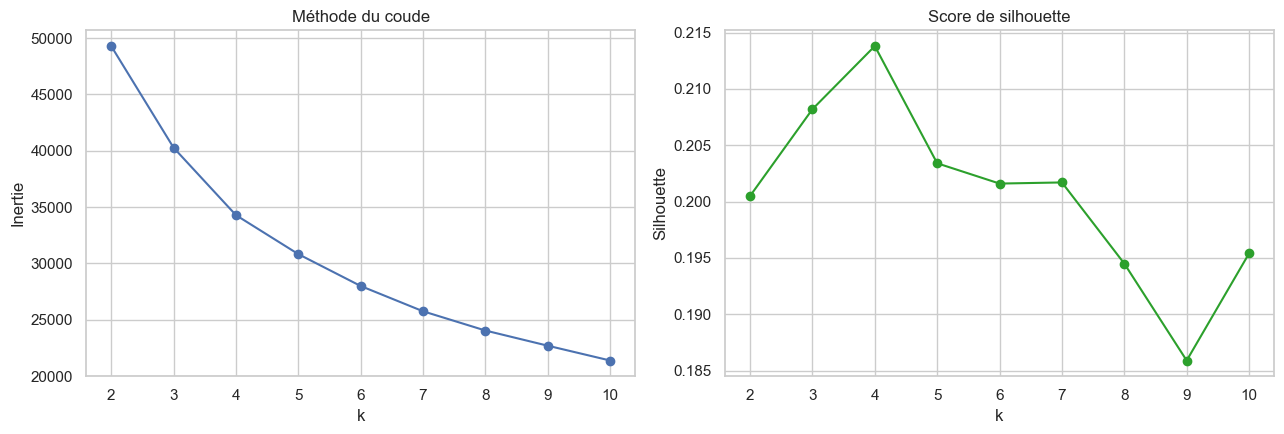

k avec la meilleure silhouette : 4


In [2]:
K_RANGE = range(2, 11)
inertias, sils = [], []

for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_train)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_train, km.labels_, sample_size=4000, random_state=42))

res = pd.DataFrame({"k": list(K_RANGE), "inertie": inertias, "silhouette": sils}).round(4)
display(res)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(res["k"], res["inertie"], marker="o")
axes[0].set_title("Méthode du coude")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertie")
axes[1].plot(res["k"], res["silhouette"], marker="o", color="tab:green")
axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

k_best_sil = int(res.loc[res["silhouette"].idxmax(), "k"])
print("k avec la meilleure silhouette :", k_best_sil)

### Décision sur k
Regarde les deux graphiques puis fixe `K` ci-dessous. Si le coude et la silhouette ne s'accordent pas, privilégie un k qui donne des clusters **interprétables** (3 ou 4 est souvent un bon compromis) et justifie ton choix dans le rapport.

In [6]:
K = k_best_sil   # <- modifie ici si tu préfères un autre k (ex : K = 3)
print("k retenu :", K)

k retenu : 4


## 3. K-Means final

In [7]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_train)

labels_train = kmeans.labels_
labels_test = kmeans.predict(X_test)     # le test est seulement projeté sur les centres appris

print("Silhouette finale (train) :",
      round(silhouette_score(X_train, labels_train, sample_size=4000, random_state=42), 4))
print("\nTaille des clusters (train) :")
print(pd.Series(labels_train).value_counts().sort_index())

Silhouette finale (train) : 0.2138

Taille des clusters (train) :
0    2072
1    2134
2    2151
3    1643
Name: count, dtype: int64


## 4. Profil des clusters
Les variables sont normalisées : une valeur de **+1** signifie « 1 écart-type au-dessus de la moyenne générale », **-1** « en dessous ». C'est ce qui permet de nommer chaque cluster (par exemple « couple élevé, faible vitesse »).

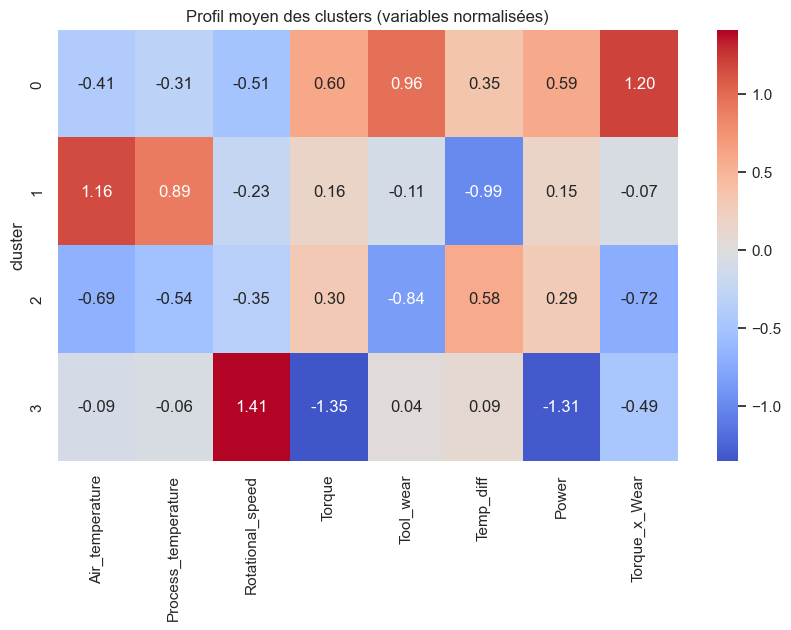

In [8]:
profile = X_train.assign(cluster=labels_train).groupby("cluster").mean()

plt.figure(figsize=(10, 0.9 * K + 2))
sns.heatmap(profile, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Profil moyen des clusters (variables normalisées)")
plt.show()

## 5. Visualisation des clusters dans le plan PCA

c:\Users\ghait\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


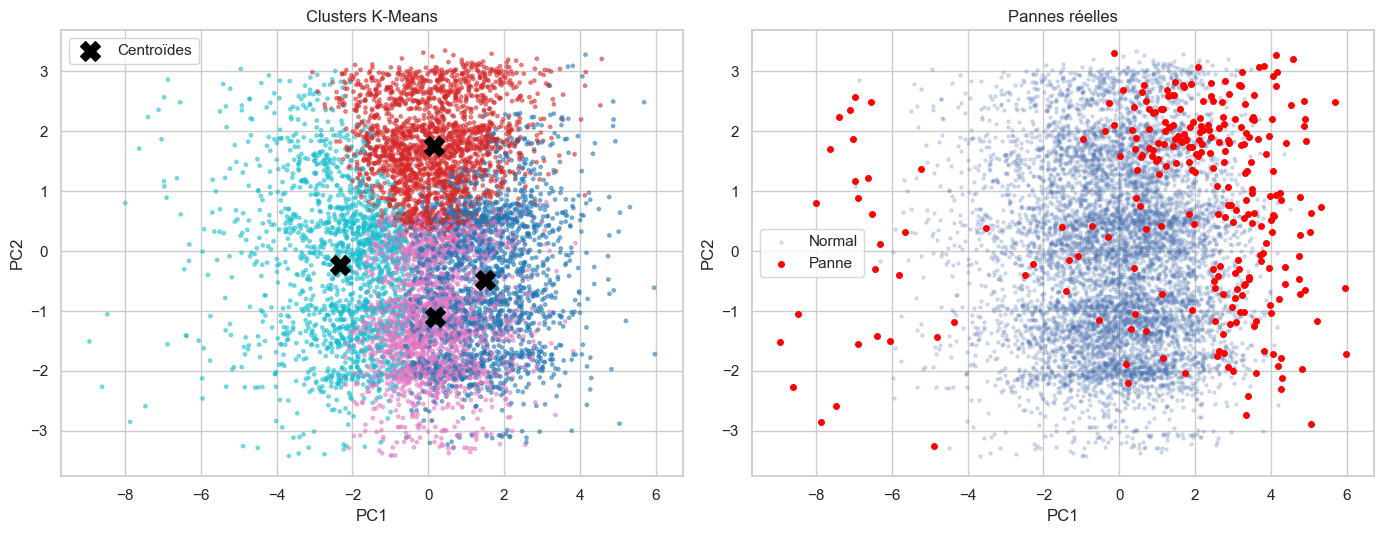

In [9]:
pca2 = PCA(n_components=2, random_state=42).fit(X_train)
Z = pca2.transform(X_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sc = axes[0].scatter(Z[:, 0], Z[:, 1], c=labels_train, cmap="tab10", s=6, alpha=0.5)
centers2 = pca2.transform(kmeans.cluster_centers_)
axes[0].scatter(centers2[:, 0], centers2[:, 1], c="black", marker="X", s=200, label="Centroïdes")
axes[0].set_title("Clusters K-Means")
axes[0].legend()

m1 = (y_train == 1).values
axes[1].scatter(Z[~m1, 0], Z[~m1, 1], s=5, alpha=0.2, label="Normal")
axes[1].scatter(Z[m1, 0], Z[m1, 1], s=16, color="red", label="Panne")
axes[1].set_title("Pannes réelles")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

## 6. Croisement clusters / pannes
Le clustering n'a jamais vu la cible. Si un cluster a un taux de pannes très supérieur à la moyenne, c'est un groupe **à risque**.

Taux de pannes global (train) : 3.39 %

--- Train ---


,Nb machines,Nb pannes,Taux de pannes (%),Part des pannes totales (%)
cluster,,,,
0,2072,120,5.79,44.3
1,2134,98,4.59,36.2
2,2151,18,0.84,6.6
3,1643,35,2.13,12.9


--- Test ---


,Nb machines,Nb pannes,Taux de pannes (%),Part des pannes totales (%)
cluster,,,,
0,513,32,6.24,47.1
1,540,26,4.81,38.2
2,544,1,0.18,1.5
3,403,9,2.23,13.2


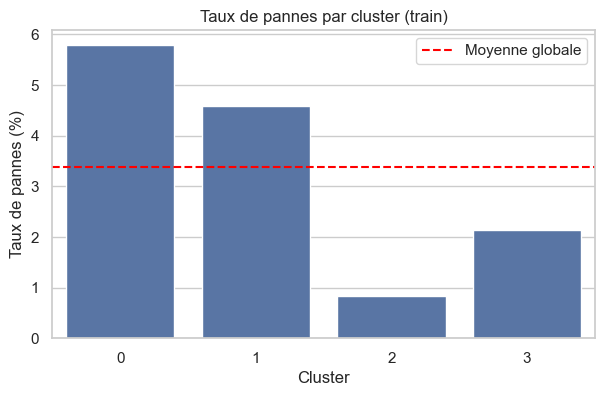

In [10]:
def cluster_table(labels, y):
    t = pd.DataFrame({"cluster": labels, "panne": y.values})
    g = t.groupby("cluster")["panne"].agg(["count", "sum", "mean"])
    g.columns = ["Nb machines", "Nb pannes", "Taux de pannes"]
    g["Taux de pannes (%)"] = (g["Taux de pannes"] * 100).round(2)
    g["Part des pannes totales (%)"] = (g["Nb pannes"] / g["Nb pannes"].sum() * 100).round(1)
    return g.drop(columns="Taux de pannes")

tab_train = cluster_table(labels_train, y_train)
tab_test = cluster_table(labels_test, y_test)
print("Taux de pannes global (train) :", round(y_train.mean() * 100, 2), "%")
print("\n--- Train ---"); display(tab_train)
print("--- Test ---"); display(tab_test)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=tab_train.index, y=tab_train["Taux de pannes (%)"], ax=ax)
ax.axhline(y_train.mean() * 100, color="red", linestyle="--", label="Moyenne globale")
ax.set_title("Taux de pannes par cluster (train)")
ax.set_xlabel("Cluster")
ax.legend()
plt.show()

## 7. Détection d'anomalies par distance au centroïde
Une machine très éloignée du centre de son cluster est **atypique**. On fixe un seuil sur le train (percentile), puis on l'applique au test.

In [11]:
def dist_to_centroid(model, X):
    # distance à chaque centroïde, on garde la plus petite (celle du cluster assigné)
    return model.transform(X).min(axis=1)

d_train = dist_to_centroid(kmeans, X_train)
d_test = dist_to_centroid(kmeans, X_test)

rows = []
for q in [90, 95, 97, 99]:
    thr = np.percentile(d_train, q)
    flag = d_test > thr
    n_flag = int(flag.sum())
    tp = int(((flag) & (y_test.values == 1)).sum())
    rows.append({
        "Percentile": q,
        "Seuil": round(thr, 3),
        "Machines signalées (test)": n_flag,
        "Pannes parmi elles": tp,
        "Precision (%)": round(tp / n_flag * 100, 2) if n_flag else 0,
        "Recall (%)": round(tp / y_test.sum() * 100, 2),
    })
anom = pd.DataFrame(rows)
print("Taux de pannes de base (test) :", round(y_test.mean() * 100, 2), "%")
display(anom)

Taux de pannes de base (test) : 3.4 %


,Percentile,Seuil,Machines signalées (test),Pannes parmi elles,Precision (%),Recall (%)
0,90,2.723,210,34,16.19,50.00
1,95,3.075,96,27,28.12,39.71
2,97,3.351,55,23,41.82,33.82
3,99,4.089,14,10,71.43,14.71


In [ ]:
plt.figure(figsize=(9, 4))
sns.histplot(x=d_train, hue=y_train.values, stat="density", common_norm=False, bins=50)
plt.axvline(np.percentile(d_train, 95), color="red", linestyle="--", label="Seuil 95e percentile")
plt.title("Distance au centroïde : machines normales vs en panne (train)")
plt.xlabel("Distance au centroïde le plus proche")
plt.legend(title="", labels=["Seuil 95e", "Panne", "Normal"])
plt.show()

## 8. Sauvegarde

In [12]:
joblib.dump(kmeans, MODELS / "kmeans.pkl")
joblib.dump({"km_cols": km_cols, "threshold_95": float(np.percentile(d_train, 95)),
             "threshold_99": float(np.percentile(d_train, 99))}, MODELS / "kmeans_meta.pkl")
print("kmeans.pkl et kmeans_meta.pkl sauvegardés.")

kmeans.pkl et kmeans_meta.pkl sauvegardés.


## Résumé à retenir pour le rapport
1. k choisi avec la méthode du coude et la silhouette (justifier le choix final).
2. Chaque cluster est décrit par son profil moyen (heatmap) et reçoit un nom métier.
3. Le croisement clusters/pannes dit si K-Means isole un groupe à risque, sans avoir utilisé la cible.
4. La distance au centroïde donne un détecteur d'anomalies simple. Compare sa precision/recall au taux de base : s'il est meilleur que le hasard, il apporte de l'information.
5. Limites : K-Means suppose des clusters sphériques et les pannes de ce dataset dépendent de seuils sur des combinaisons de variables, donc un clustering non supervisé ne les isolera que partiellement. Cela motive l'étape suivante : la classification supervisée.